# Carga del dataset

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from scipy.stats import chi2_contingency
import itertools

# Elige el que necesites (Clasificación o Regresión)
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import classification_report, r2_score


In [4]:
df = pd.read_csv("datos/df_clean.csv")

In [5]:
df.head()

,edad,genero,horas_diarias_pantalla,horas_redes_sociales,horas_videojuegos,horas_trabajo/estudio,horas_sueño,notificaciones_por_dia,aperturas_apps_por_dia,tiempo_pantalla_finde,nivel_estres,impacto_academico/laboral,etiqueta_de_adiccion,horas_ocio,ratio_finde_diario,estado_adiccion,diferencia_finde
0,21,Male,3.23,2.01,0.89,4.55,7.55,248,154,3.95,Medium,Yes,0,2.90,1.222910,No adicto,0.72
1,24,Other,5.09,3.81,2.24,4.44,7.66,127,71,6.71,Medium,Yes,0,6.05,1.318271,No adicto,1.62
2,31,Other,6.06,1.36,3.83,2.35,4.92,44,106,8.68,High,No,0,5.19,1.432343,No adicto,2.62
3,32,Other,7.83,5.85,1.51,3.54,8.23,178,107,9.77,High,Yes,1,7.36,1.247765,Adicto,1.94
4,25,Male,9.96,5.92,3.42,5.27,6.21,136,177,12.55,Low,No,1,9.34,1.260040,Adicto,2.59


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   edad                       7500 non-null   int64  
 1   genero                     7500 non-null   str    
 2   horas_diarias_pantalla     7500 non-null   float64
 3   horas_redes_sociales       7500 non-null   float64
 4   horas_videojuegos          7500 non-null   float64
 5   horas_trabajo/estudio      7500 non-null   float64
 6   horas_sueño                7500 non-null   float64
 7   notificaciones_por_dia     7500 non-null   int64  
 8   aperturas_apps_por_dia     7500 non-null   int64  
 9   tiempo_pantalla_finde      7500 non-null   float64
 10  nivel_estres               7500 non-null   str    
 11  impacto_academico/laboral  7500 non-null   str    
 12  etiqueta_de_adiccion       7500 non-null   int64  
 13  horas_ocio                 7500 non-null   float64
 14  rat

In [7]:
df = df.rename(columns = {
    'edad': 'age',
    'genero': 'sex',
    'horas_diarias_pantalla': 'daily_screen_hrs',
    'horas_redes_sociales': 'social_hrs',
    'horas_videojuegos': 'gaming_hrs',
    'horas_trabajo/estudio': 'work_study_hrs',
    'horas_sueño': 'sleep_hrs',
    'notificaciones_por_dia': 'daily_notifs',
    'aperturas_apps_por_dia': 'daily_app_opens',
    'tiempo_pantalla_finde': 'wknd_screen_hrs',
    'nivel_estres': 'stress_level',
    'impacto_academico/laboral': 'acad_work_impact',
    'etiqueta_de_adiccion': 'addiction_label',
    'horas_ocio': 'leisure_hrs',
    'ratio_finde_diario': 'wknd_daily_ratio',
    'estado_adiccion': 'addiction_status',
    'diferencia_finde': 'wknd_diff'
})

df.head()

,age,sex,daily_screen_hrs,social_hrs,gaming_hrs,work_study_hrs,sleep_hrs,daily_notifs,daily_app_opens,wknd_screen_hrs,stress_level,acad_work_impact,addiction_label,leisure_hrs,wknd_daily_ratio,addiction_status,wknd_diff
0,21,Male,3.23,2.01,0.89,4.55,7.55,248,154,3.95,Medium,Yes,0,2.90,1.222910,No adicto,0.72
1,24,Other,5.09,3.81,2.24,4.44,7.66,127,71,6.71,Medium,Yes,0,6.05,1.318271,No adicto,1.62
2,31,Other,6.06,1.36,3.83,2.35,4.92,44,106,8.68,High,No,0,5.19,1.432343,No adicto,2.62
3,32,Other,7.83,5.85,1.51,3.54,8.23,178,107,9.77,High,Yes,1,7.36,1.247765,Adicto,1.94
4,25,Male,9.96,5.92,3.42,5.27,6.21,136,177,12.55,Low,No,1,9.34,1.260040,Adicto,2.59


<Axes: >

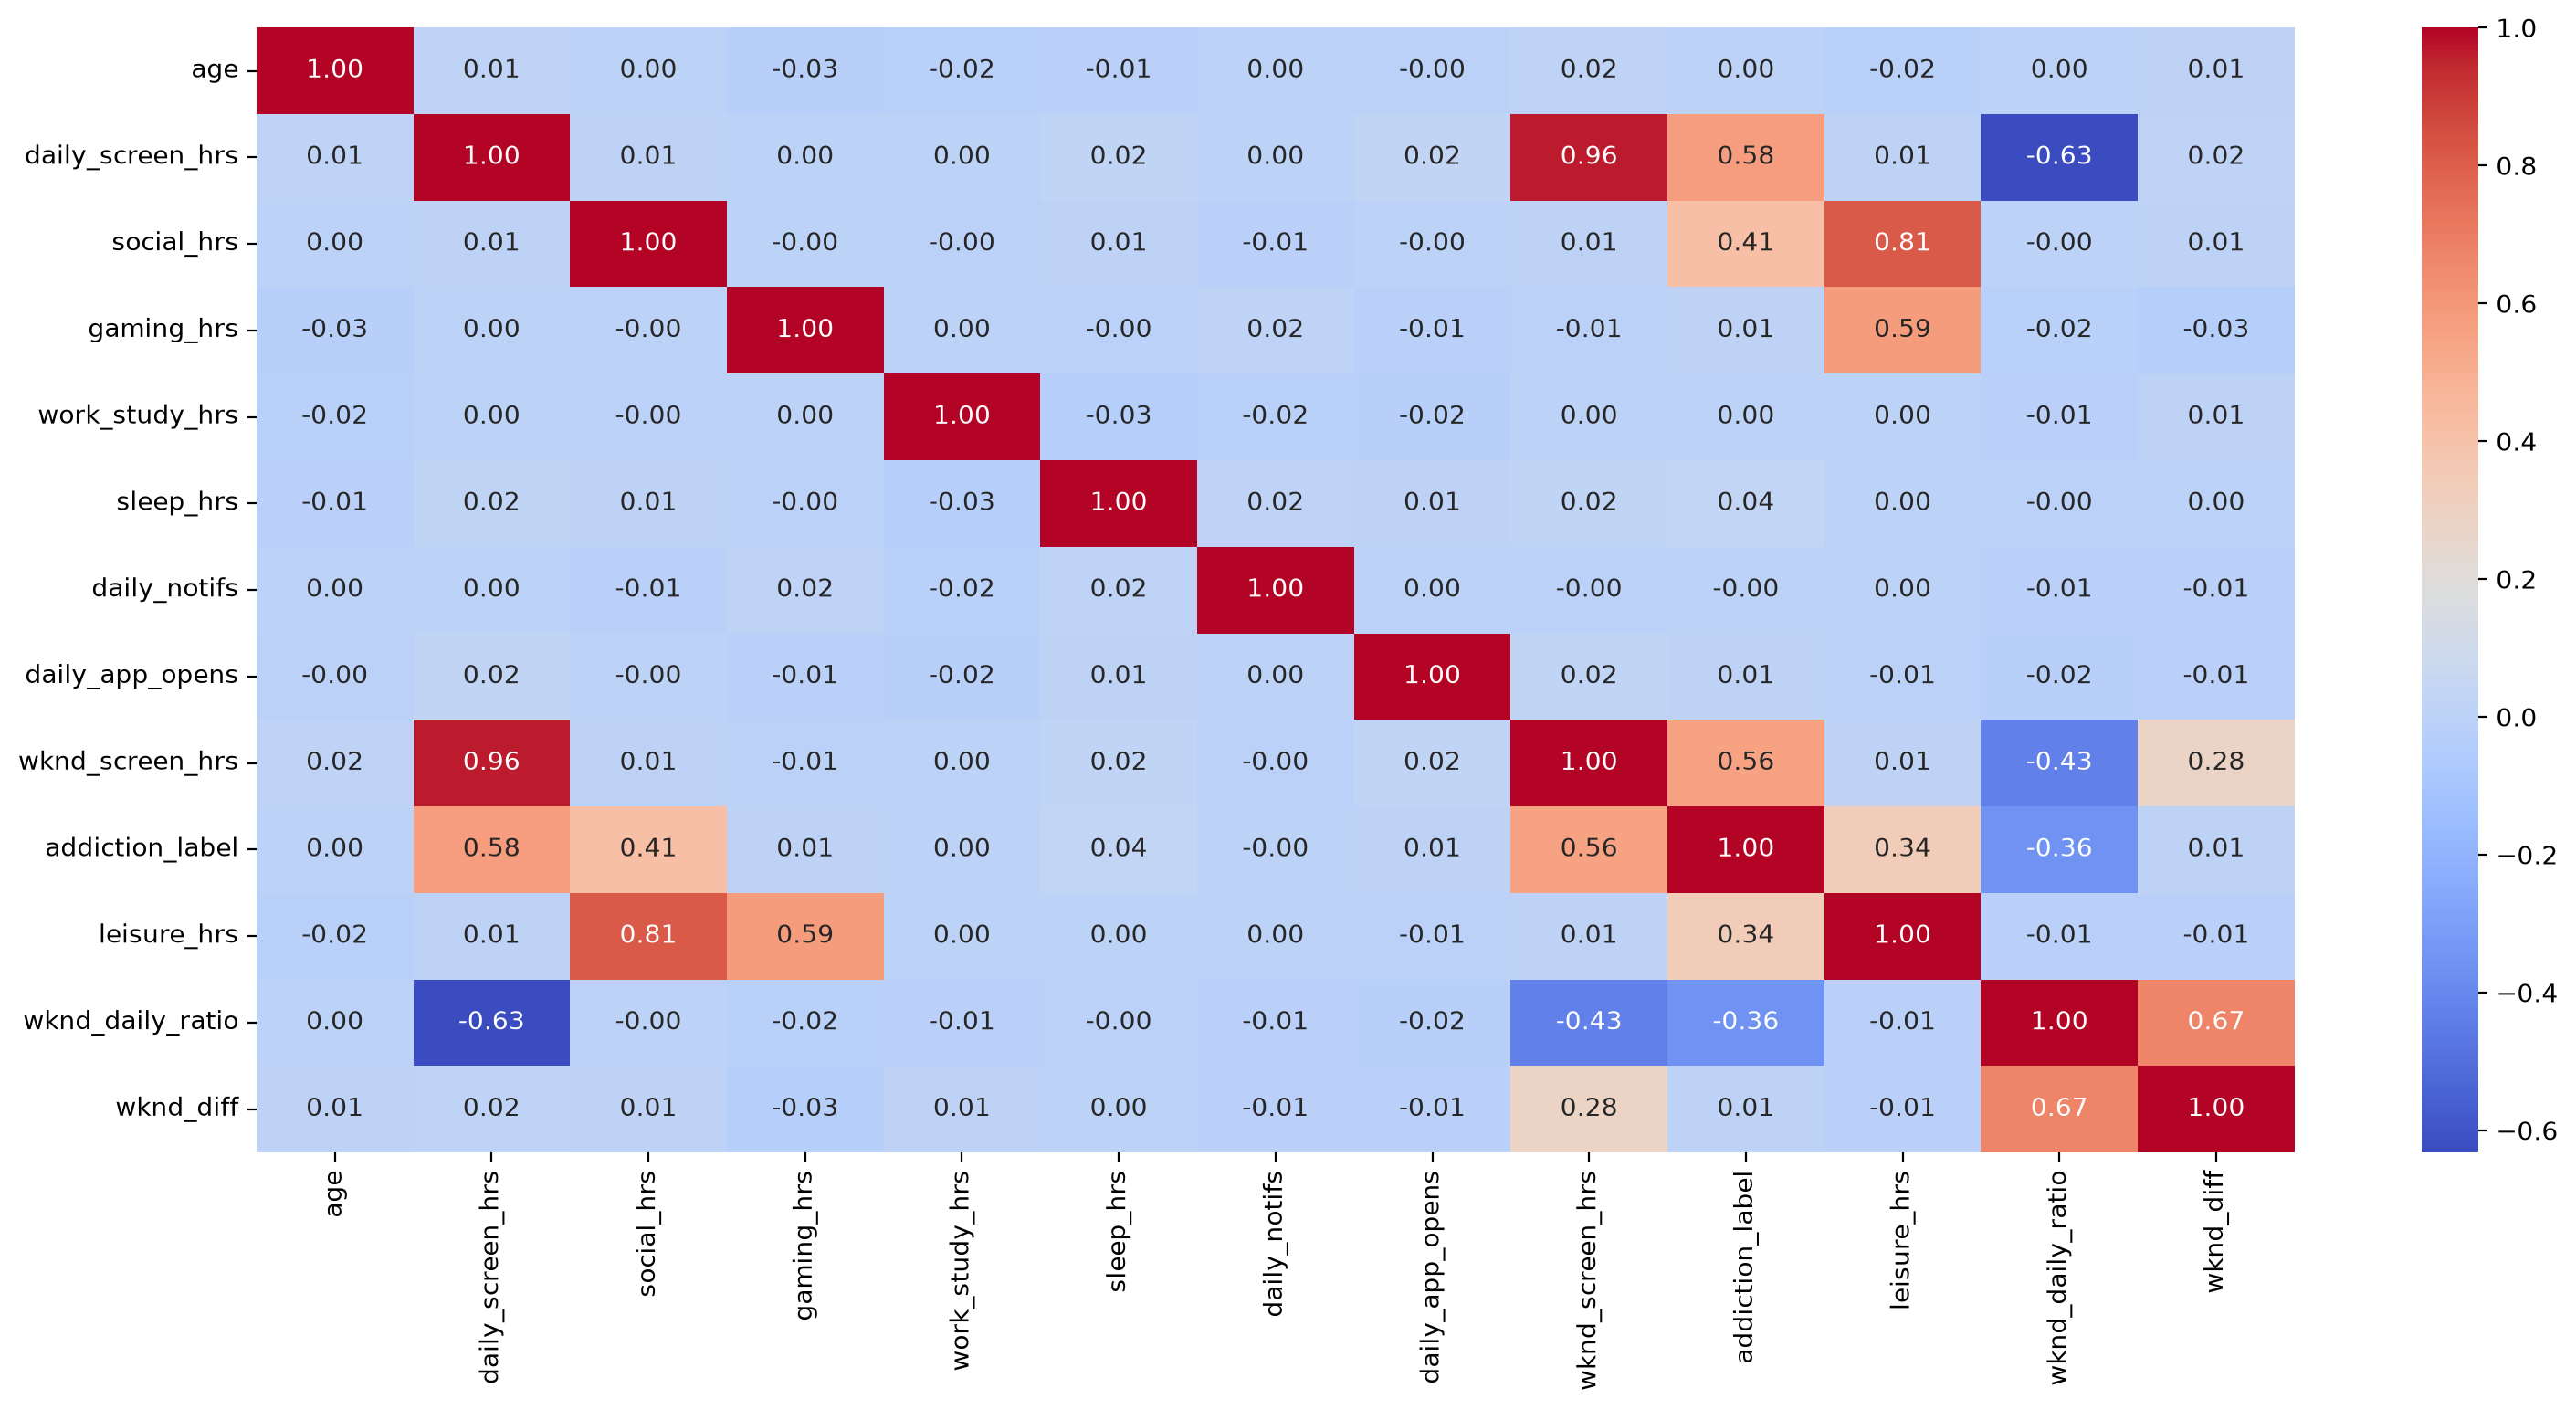

In [8]:
num = df.select_dtypes("number")
plt.figure(figsize = (18, 8))
sns.heatmap(data = num.corr(), annot = True, cmap ="coolwarm", fmt = ".2f")

In [9]:
num.info()

<class 'pandas.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               7500 non-null   int64  
 1   daily_screen_hrs  7500 non-null   float64
 2   social_hrs        7500 non-null   float64
 3   gaming_hrs        7500 non-null   float64
 4   work_study_hrs    7500 non-null   float64
 5   sleep_hrs         7500 non-null   float64
 6   daily_notifs      7500 non-null   int64  
 7   daily_app_opens   7500 non-null   int64  
 8   wknd_screen_hrs   7500 non-null   float64
 9   addiction_label   7500 non-null   int64  
 10  leisure_hrs       7500 non-null   float64
 11  wknd_daily_ratio  7500 non-null   float64
 12  wknd_diff         7500 non-null   float64
dtypes: float64(9), int64(4)
memory usage: 761.8 KB


In [10]:
onlynum = num.drop(columns="addiction_label")

<Axes: >

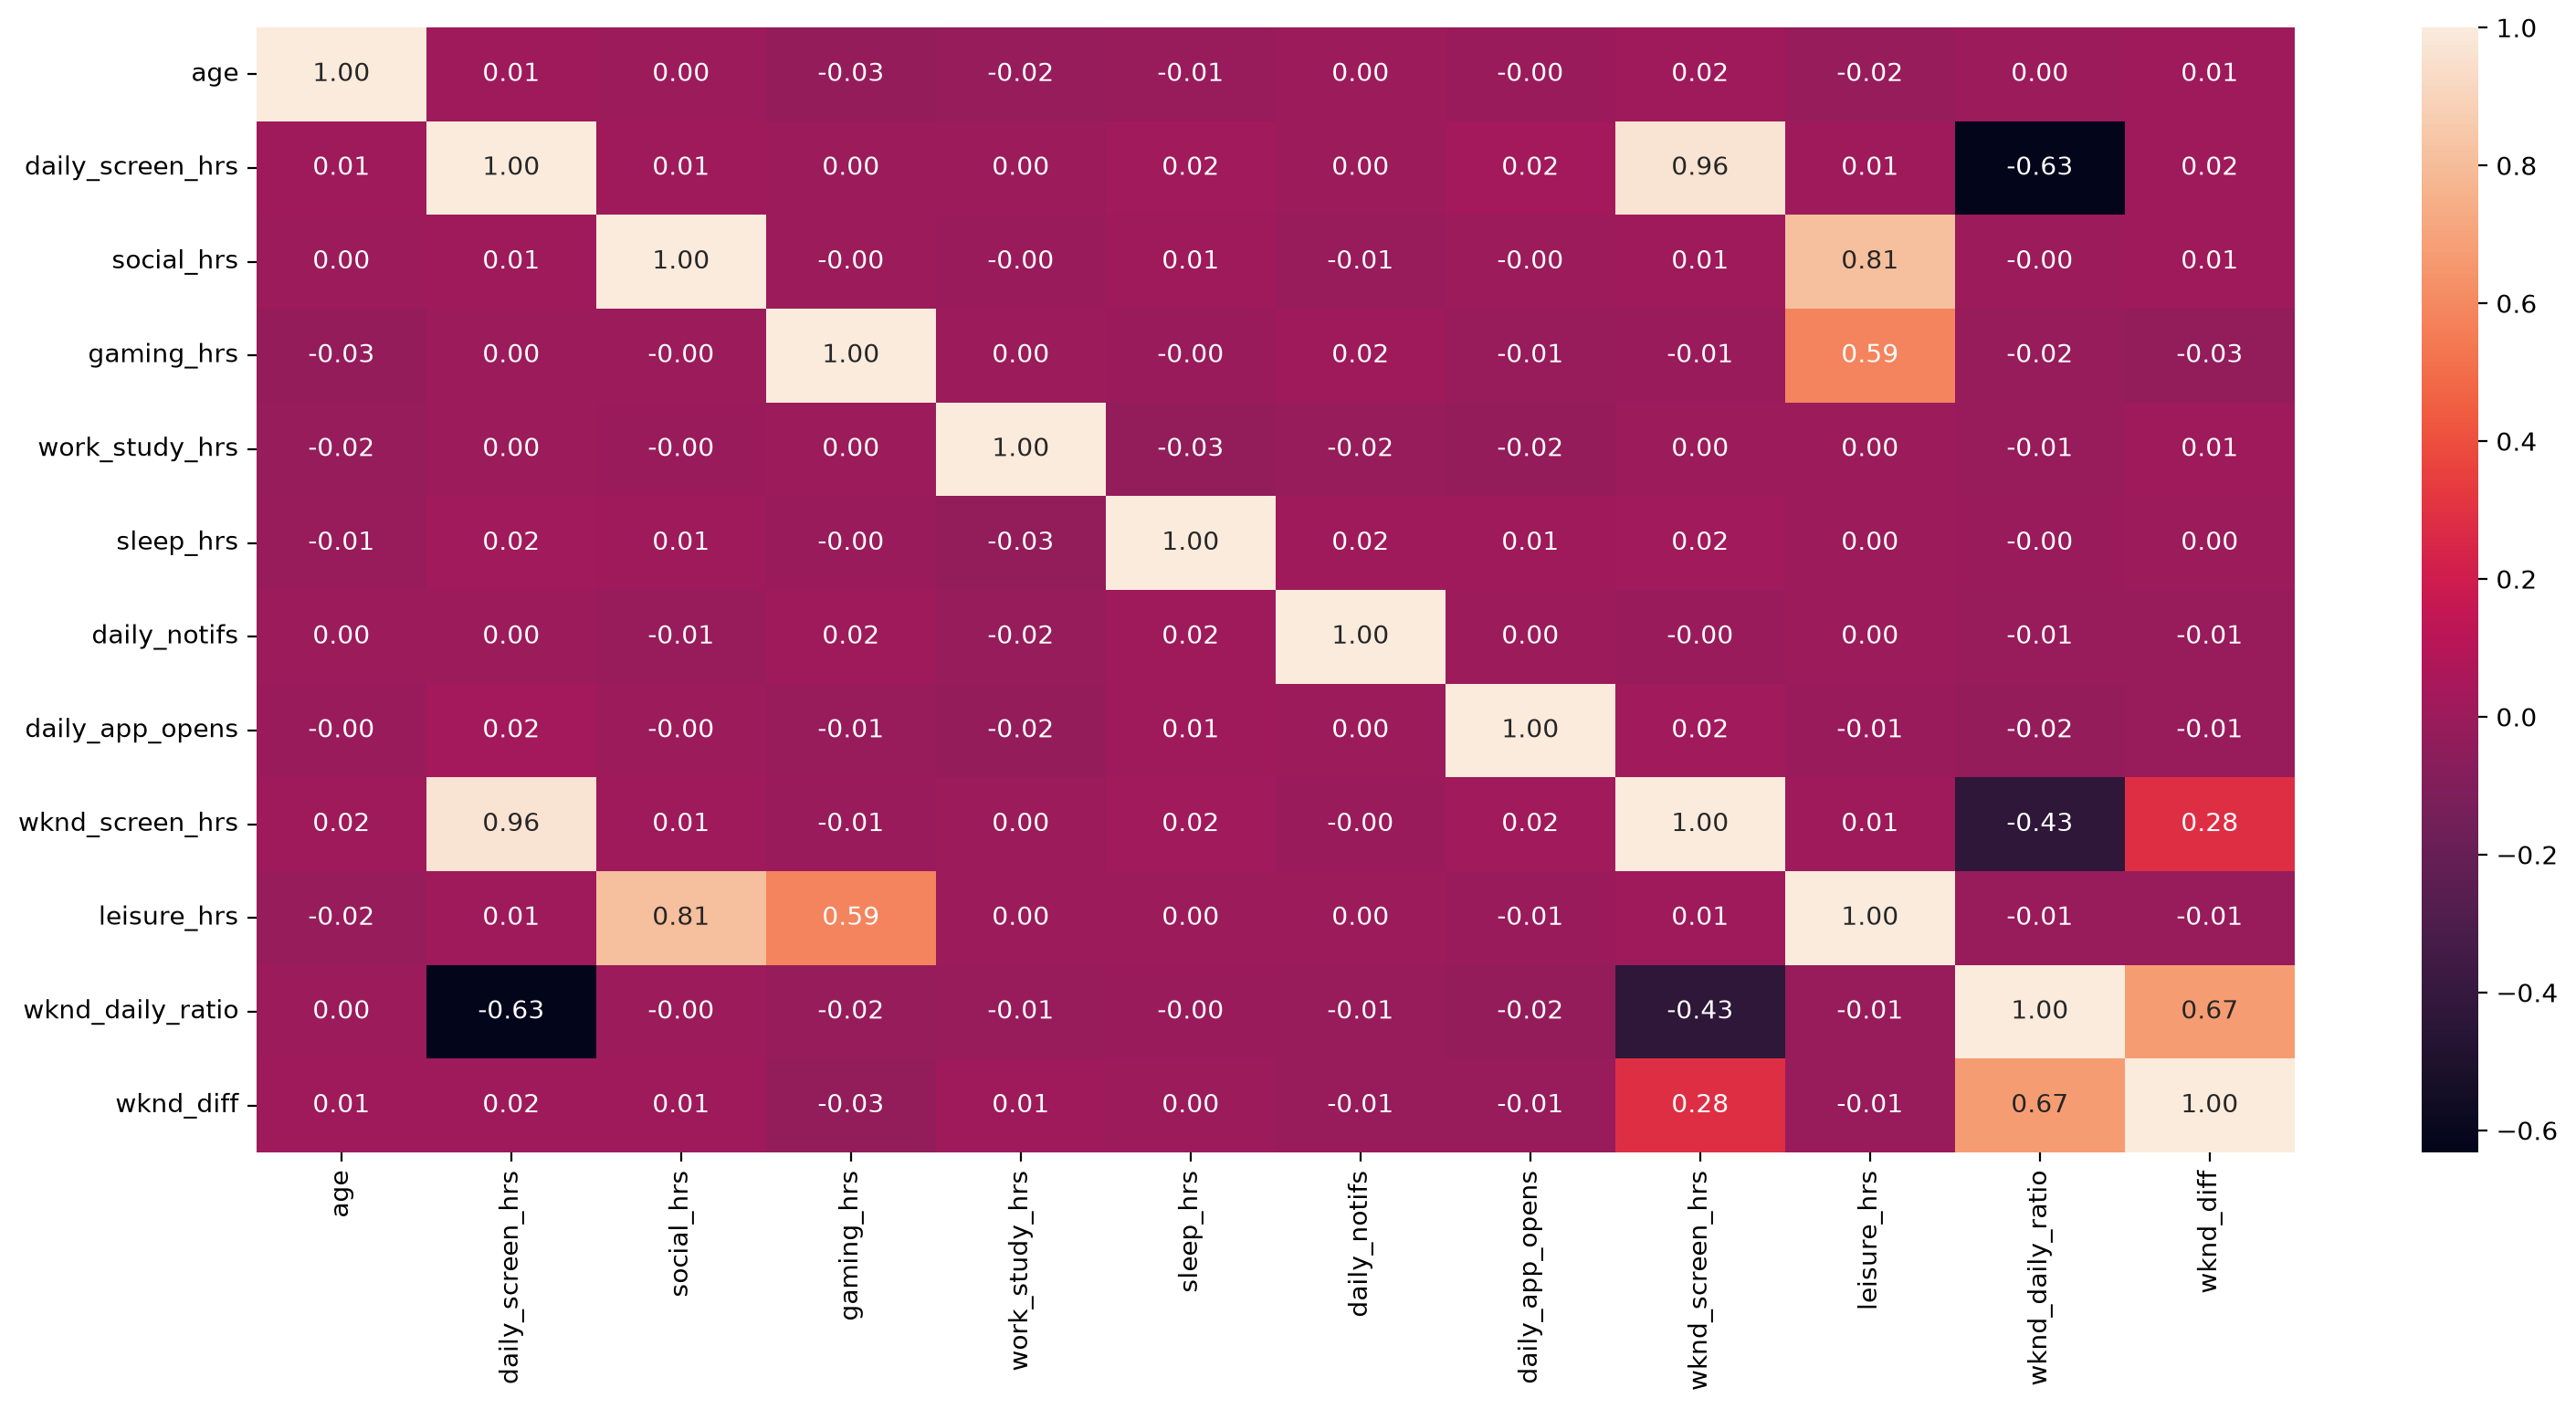

In [11]:
plt.figure(figsize = (18,8))
sns.heatmap(data = onlynum.corr(), annot = True, fmt = ".2f")

In [12]:
onlynum.info()

<class 'pandas.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               7500 non-null   int64  
 1   daily_screen_hrs  7500 non-null   float64
 2   social_hrs        7500 non-null   float64
 3   gaming_hrs        7500 non-null   float64
 4   work_study_hrs    7500 non-null   float64
 5   sleep_hrs         7500 non-null   float64
 6   daily_notifs      7500 non-null   int64  
 7   daily_app_opens   7500 non-null   int64  
 8   wknd_screen_hrs   7500 non-null   float64
 9   leisure_hrs       7500 non-null   float64
 10  wknd_daily_ratio  7500 non-null   float64
 11  wknd_diff         7500 non-null   float64
dtypes: float64(9), int64(3)
memory usage: 703.3 KB


In [13]:
cat = df.select_dtypes(include = ["object", "category"])

<positron-console-cell-13>:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.


In [14]:
cat = cat.drop(columns="addiction_status")

In [15]:
cat.info()

<class 'pandas.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   sex               7500 non-null   str  
 1   stress_level      7500 non-null   str  
 2   acad_work_impact  7500 non-null   str  
dtypes: str(3)
memory usage: 175.9 KB


In [16]:
df.columns

Index(['age', 'sex', 'daily_screen_hrs', 'social_hrs', 'gaming_hrs',
       'work_study_hrs', 'sleep_hrs', 'daily_notifs', 'daily_app_opens',
       'wknd_screen_hrs', 'stress_level', 'acad_work_impact',
       'addiction_label', 'leisure_hrs', 'wknd_daily_ratio',
       'addiction_status', 'wknd_diff'],
      dtype='str')

In [17]:
from scipy import stats

# 'binaria' contiene 0s y 1s, 'numerica' contiene valores continuos
correlacion, p_valor = stats.pointbiserialr(df['addiction_label'], df['social_hrs'])

print(f"Correlación Biserial Puntual: {correlacion}")
print(f"P-valor: {p_valor}")


Correlación Biserial Puntual: 0.41424395020781635
P-valor: 6.80530942390417e-309


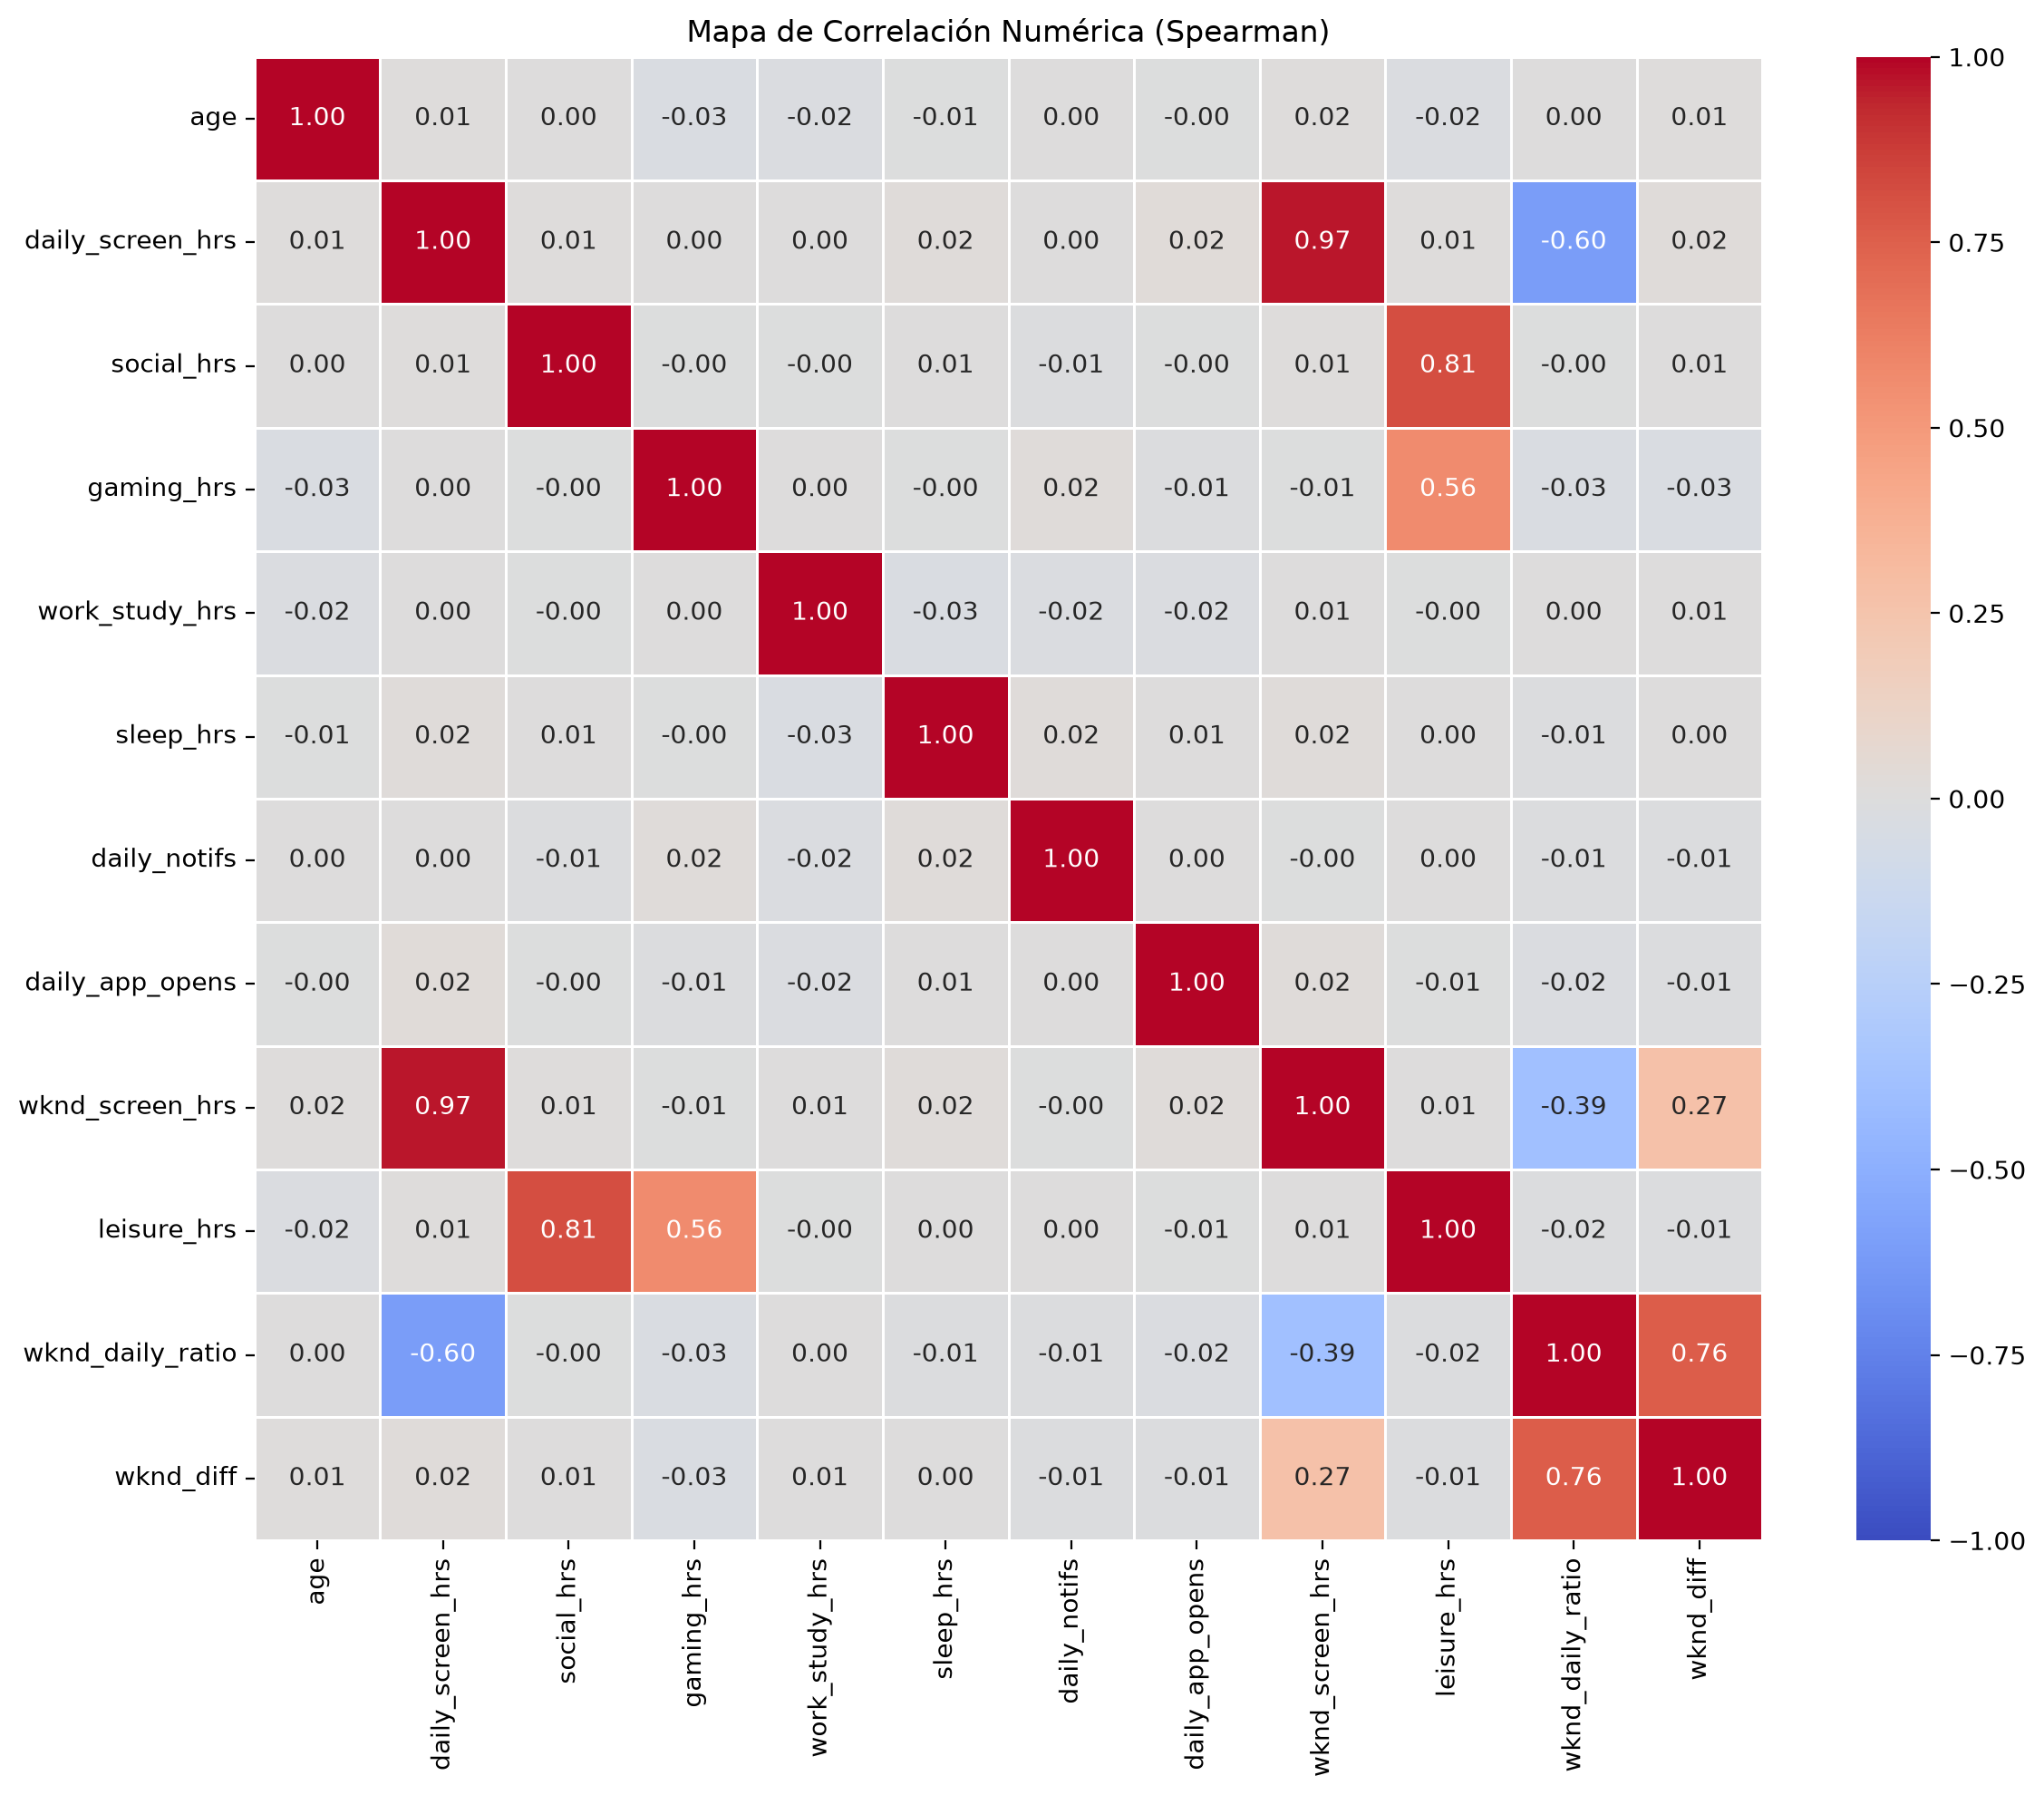

In [18]:

# 1. Seleccionar solo las variables numéricas (excluyendo la binaria si lo deseas)
numeric_cols = [
    'age',
    'daily_screen_hrs',
    'social_hrs',
    'gaming_hrs',
    'work_study_hrs',
    'sleep_hrs',
    'daily_notifs',
    'daily_app_opens',
    'wknd_screen_hrs',
    'leisure_hrs',
    'wknd_daily_ratio',
    'wknd_diff',
]
numerical_df = df[numeric_cols]

# 2. Calcular la matriz de correlación de Spearman
corr_matrix = numerical_df.corr(method='spearman')

# 3. Graficar el mapa de calor numérico
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',  # Azul (negativo), Blanco (neutro), Rojo (positivo)
    vmin=-1,
    vmax=1,
    fmt='.2f',
    linewidths=0.5,
)
plt.title("Mapa de Correlación Numérica (Spearman)")
plt.tight_layout()
plt.show()



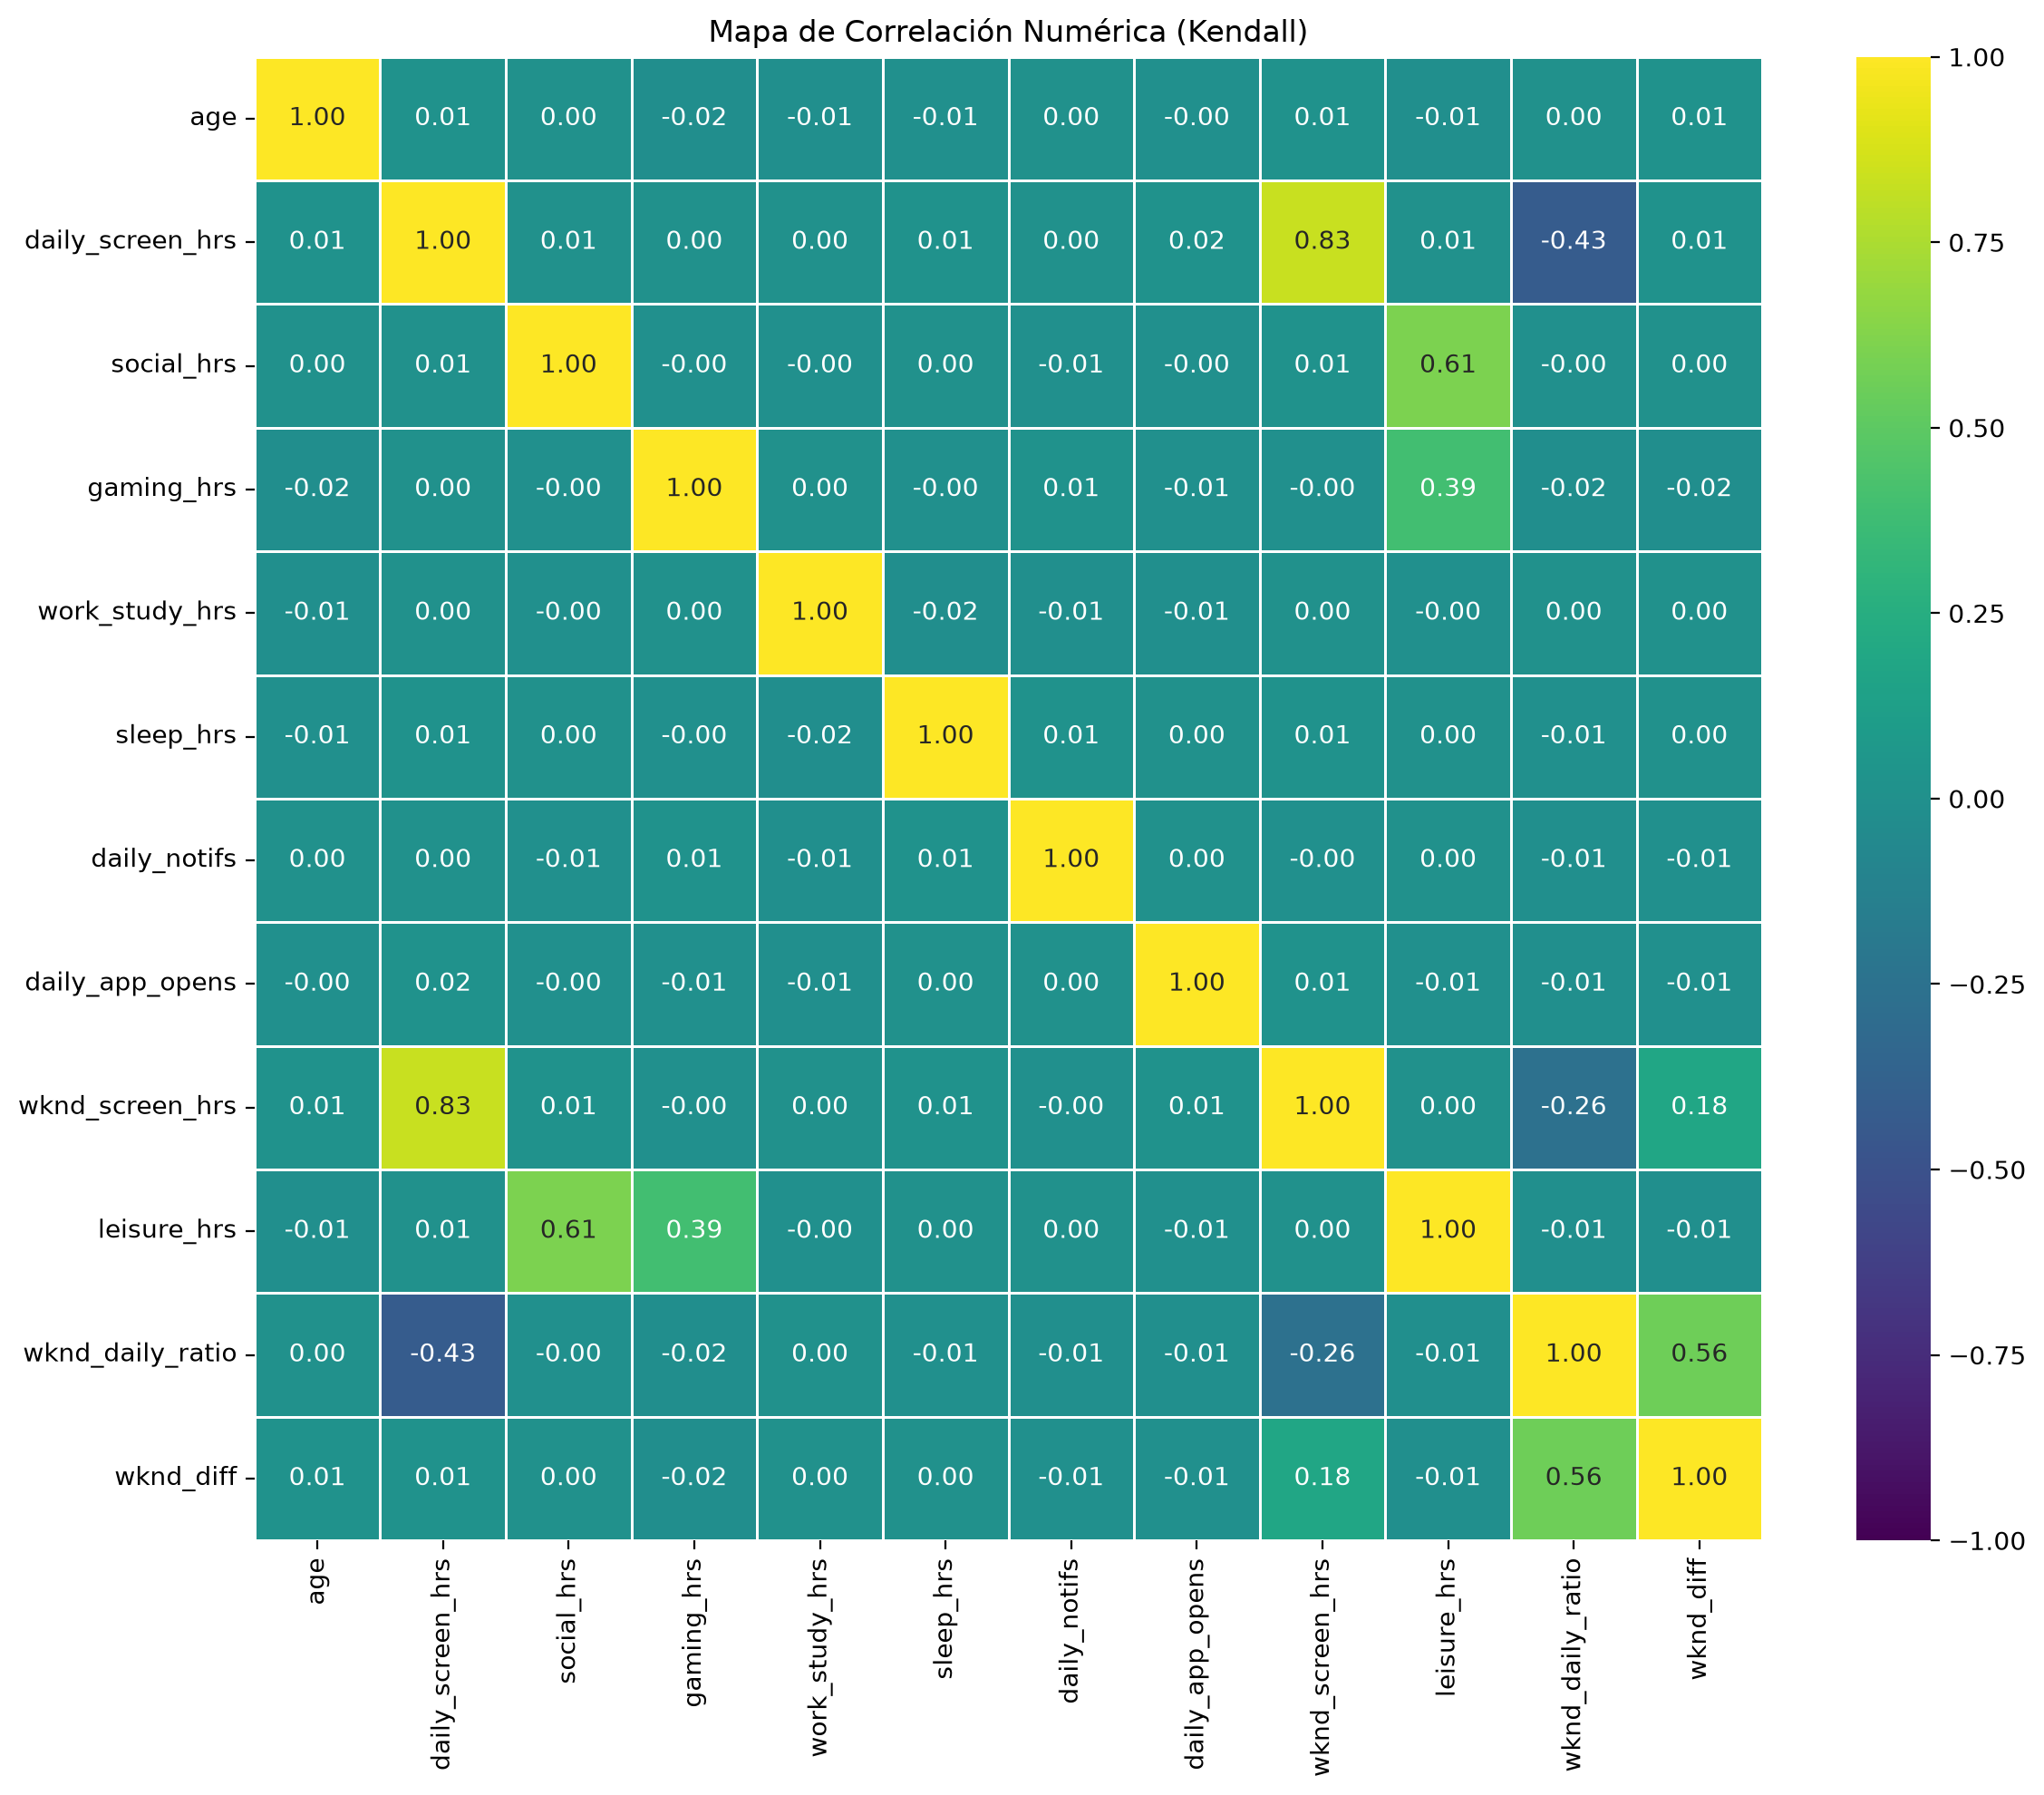

In [21]:
numerical_df = df[numeric_cols]

# 2. Calcular la matriz de correlación de Spearman
corr_matrix = numerical_df.corr(method='kendall')

# 3. Graficar el mapa de calor numérico
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    annot=True,  # Azul (negativo), Blanco (neutro), Rojo (positivo)
    vmin=-1,
    cmap = "viridis"
    ,vmax=1,
    fmt='.2f',
    linewidths=0.5,
)
plt.title("Mapa de Correlación Numérica (Kendall)")
plt.tight_layout()
plt.show()


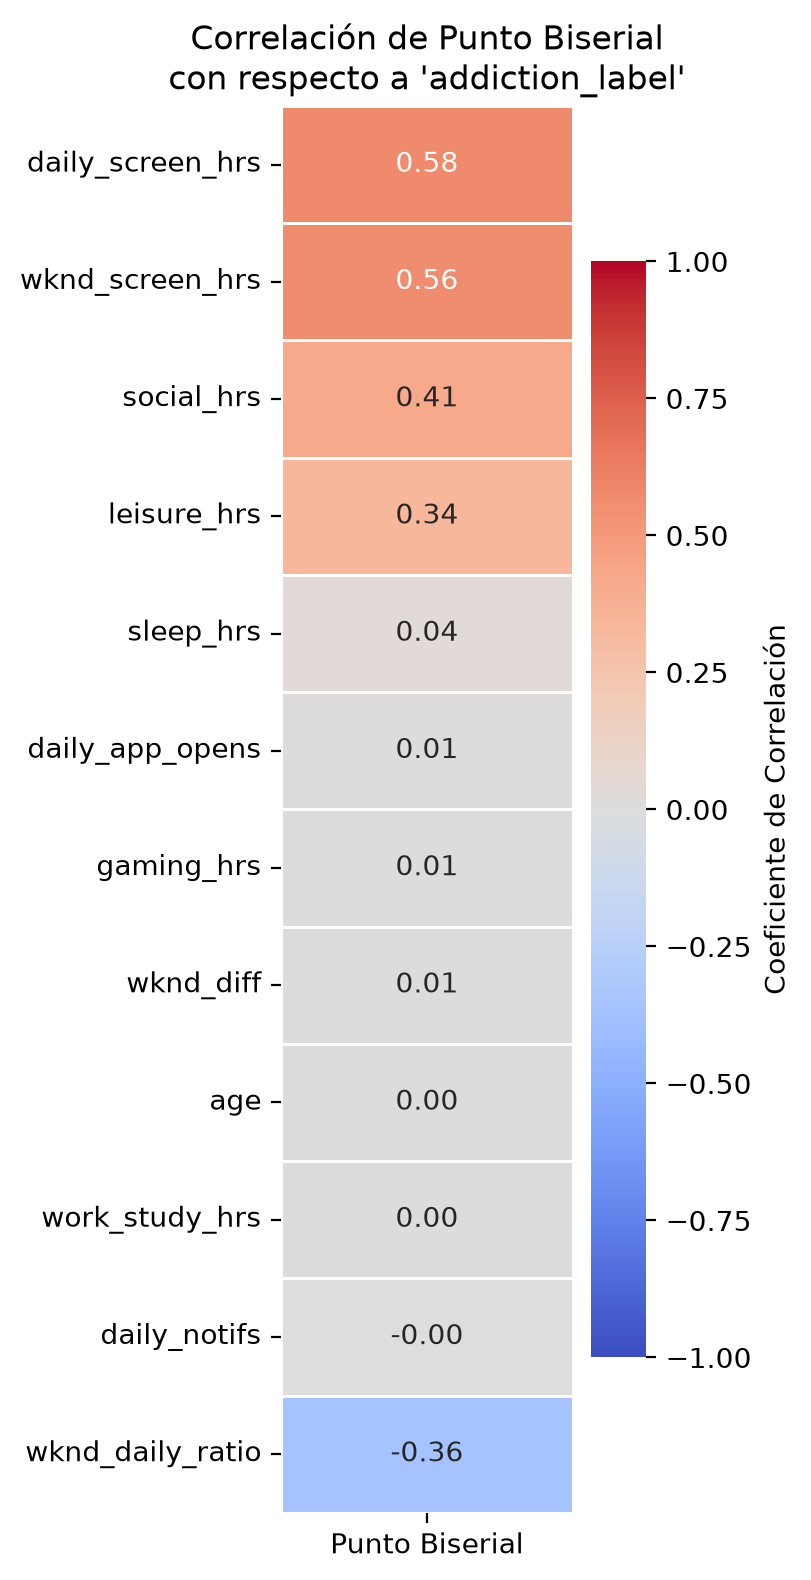

Descartamos

- sex
- leisure-hrs
- wknd_daily_ratio


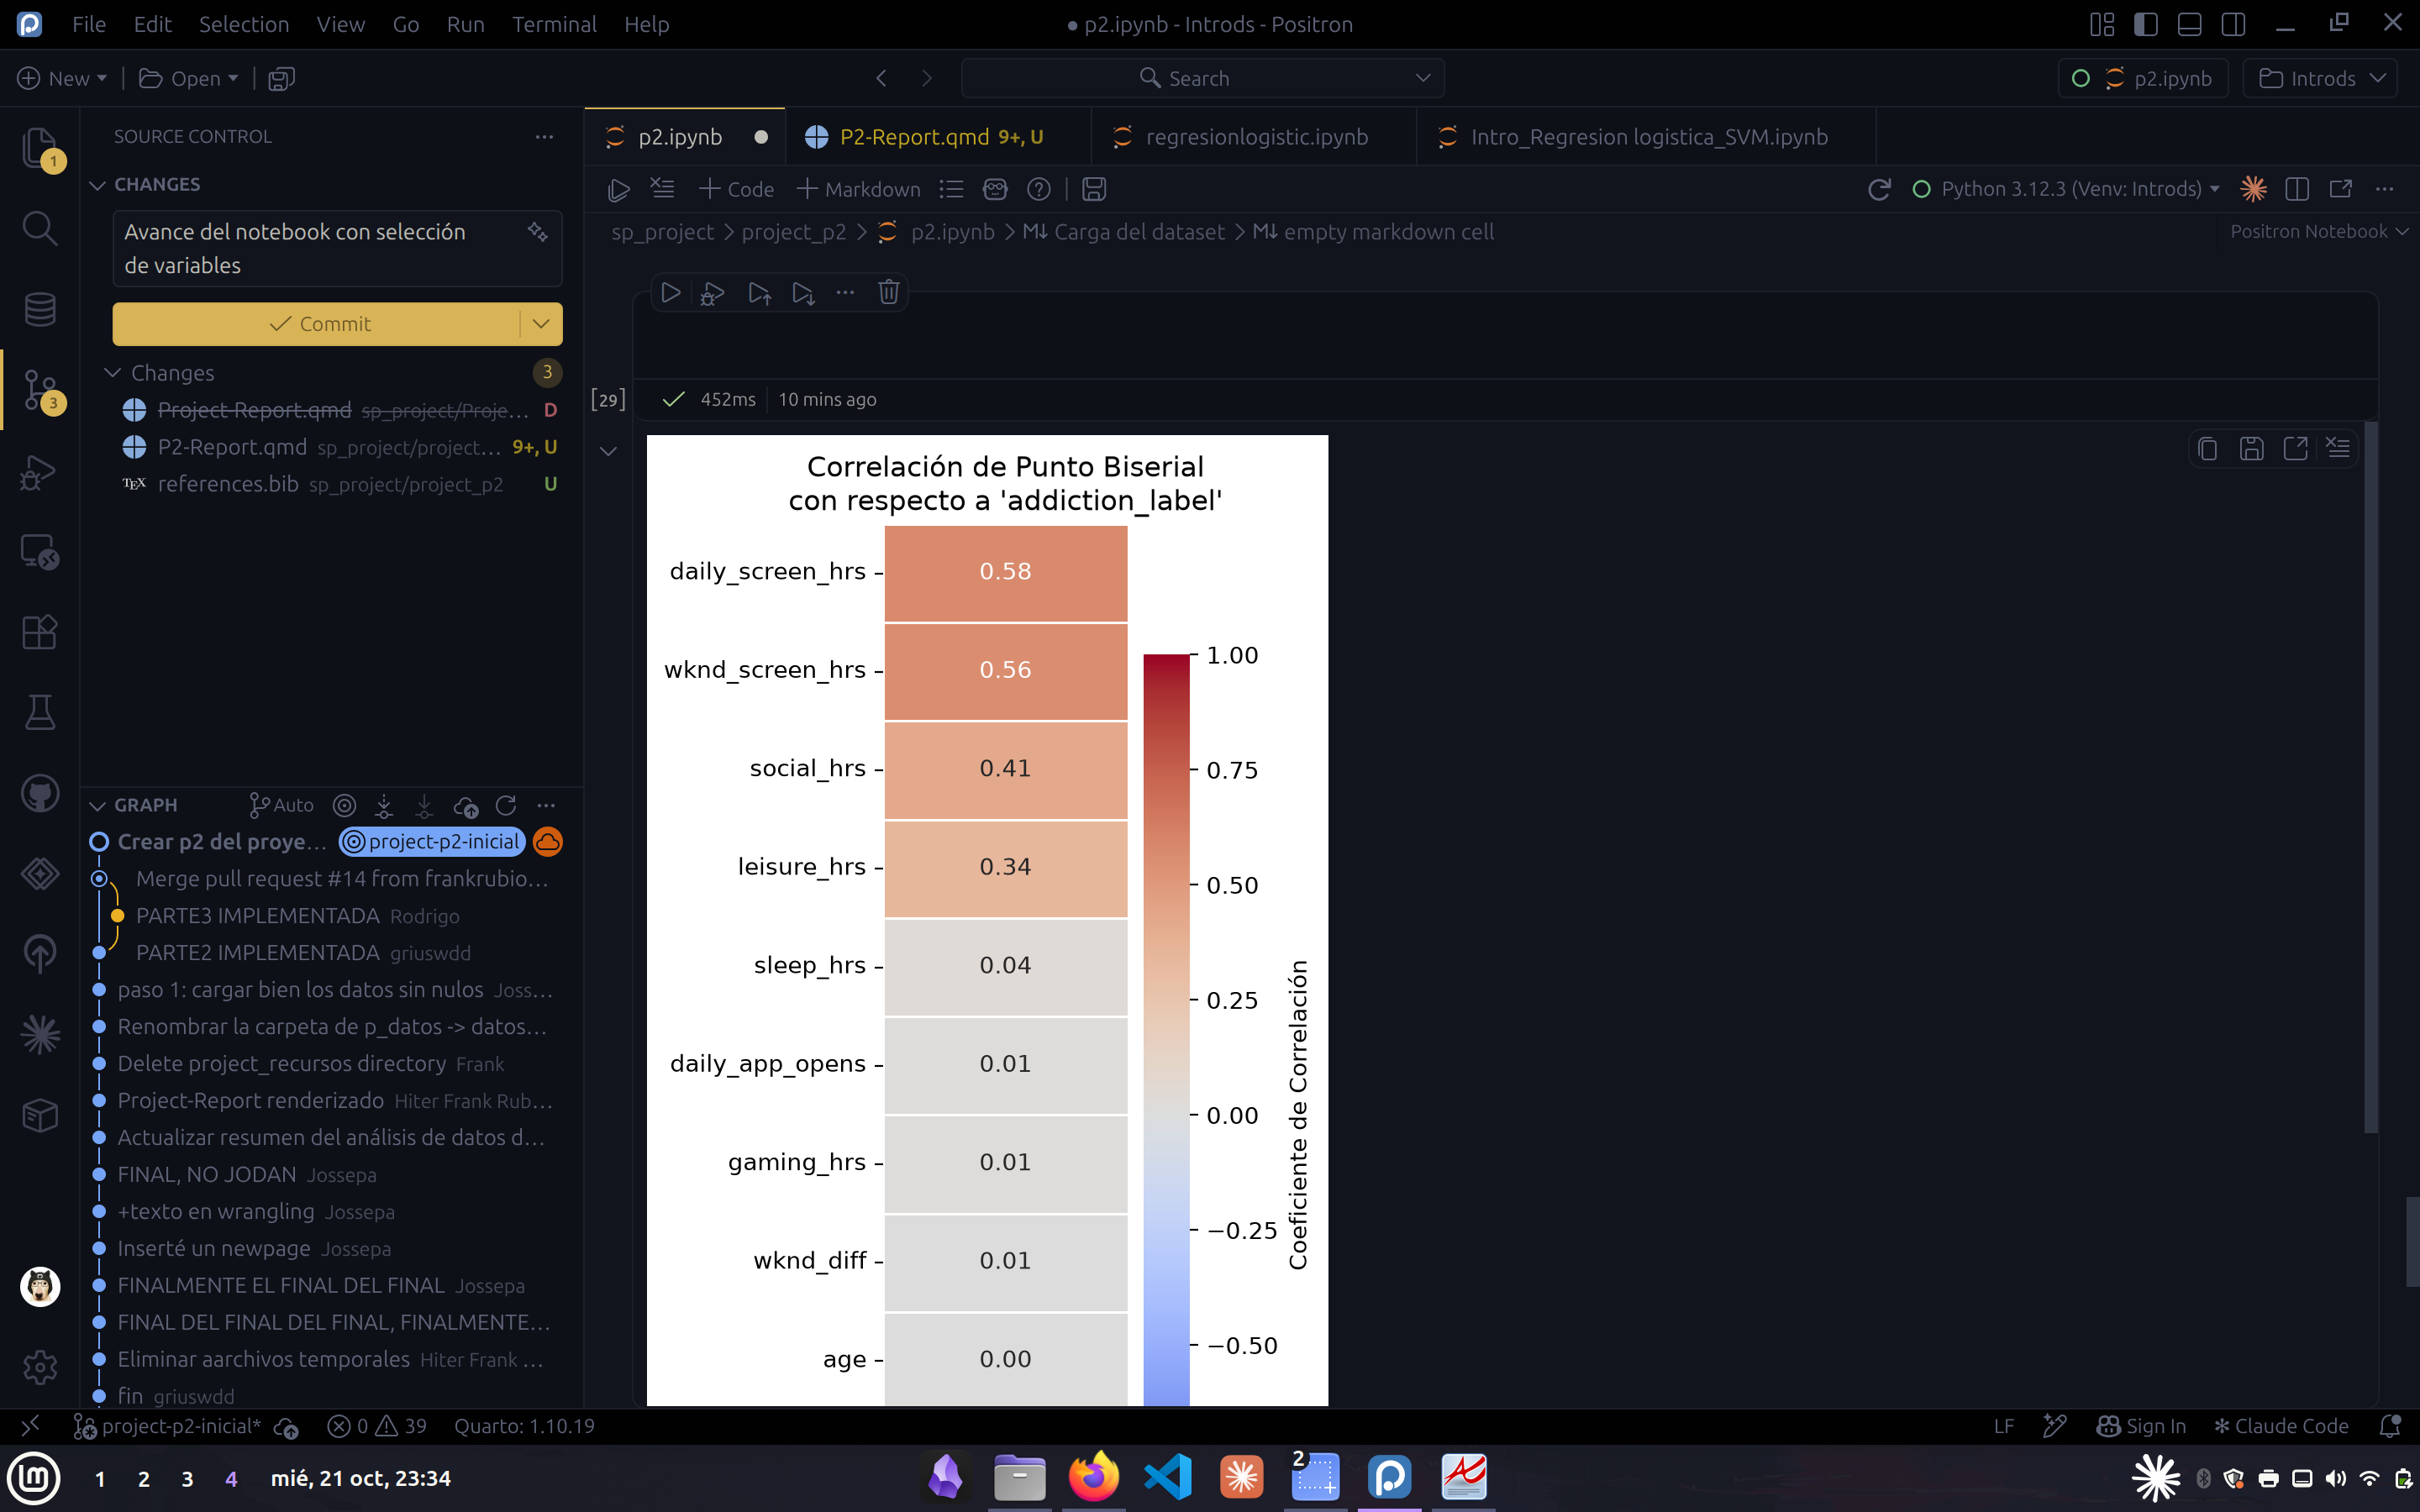

**- No se necesita eestadod e adicción, ya que es nivel de adicción pero con tipo de dato str**
-**horasdeocio provien de hoas redessocialse_horas de studio **
